# HNODE: Lorenz System

This notebook trains a Hybridized Neural ODE (HNODE) on the Lorenz system — a 3-dimensional chaotic ODE.
It is the simplest of the four examples: the state is low-dimensional and there is no encoder/decoder.

**Data**: Generated on-the-fly by numerical integration; no external data required.

**Checkpoint**: Set `CHECKPOINT_PATH` to a `.pt` file to resume from a saved checkpoint,
or set it to `None` to train from scratch.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from ode_datasets import lorenz_soln, StaggeredODEDataset, StaggeredODEDataLoader
from hybrid_node_solver import HybridNODESolver
from neural_networks import CrossAttnTransformer
from soap import SOAP

torch.set_default_dtype(torch.float64)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
print(f"Using device: {device}")

Using device: cuda


## Configuration

In [2]:
# Path to a saved checkpoint to resume training, or None to train from scratch.
CHECKPOINT_PATH = "lorenz_prod_day3.pt"
SAVE_PATH = "lorenz_checkpoint.pt"
SAVE_EVERY = 1000  # save every N optimizer steps

## Dataset

In [3]:
delta_t = 0.1
N_t = 11  # number of collocation points per rollout (M = N_t - 1 = 10 intervals)
N = 11  # number of training rollouts
num_fields = 3  # state dimension
batch_size = 1024

dataset = StaggeredODEDataset(
    delta_t,
    N_t,
    N,
    num_rollouts_to_integrate=N * 10_000,
    ode_function=lorenz_soln,
    device=device,
)
delta_t = delta_t / dataset.t_scale
dataloader = StaggeredODEDataLoader(dataset, batch_size=batch_size, shuffle=True)
print(f"Dataset ready. t_scale={dataset.t_scale:.4f}, scaled delta_t={delta_t:.6f}")

Dataset ready. t_scale=0.1342, scaled delta_t=0.745267


## Model

In [4]:
nn_rhs_model = CrossAttnTransformer(
    problem_dim=num_fields,
    latent_dim=64 * 4,
    num_blocks=3,
    num_heads=4,
    dropout_rate=0,
    activation=torch.nn.Tanh(),
).to(device)

solver = HybridNODESolver(
    nn_rhs_model,
    delta_t,
    N_t,
    num_fields,
    N,
    backprop_type="matrix_free",
    use_manual_jacobian=True,
    use_sparse_solver=False,
    use_cpu_solver=False,
    verbose=False,
    device=device,
)

n_params = sum(p.numel() for p in nn_rhs_model.parameters())
print(f"Model parameters: {n_params:,}")

Model parameters: 3,158,283


/home/kinch/PIMI-Lab/neural_odes/hnode_code/hybrid_node_solver.py:286: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at /pytorch/aten/src/ATen/SparseCsrTensorImpl.cpp:53.)
  M_p0 = p0_eval @ p0_eval.T


## Optimizer and Checkpoint

In [5]:
def get_param_groups(model, weight_decay=1e-4):
    """Separate transformer params into decay / no-decay groups (standard practice)."""
    decay, no_decay = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if param.ndim <= 1 or "bias" in name or "norm" in name.lower() or "ln" in name:
            no_decay.append(param)
        else:
            decay.append(param)
    return [
        {"params": decay, "weight_decay": weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ]


optimizer = SOAP(
    get_param_groups(nn_rhs_model),
    precondition_frequency=10,
    lr=1e-4,
)

loss_history = []

if CHECKPOINT_PATH is not None:
    import os

    if os.path.exists(CHECKPOINT_PATH):
        checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
        # Handle both key conventions that appear across saves
        state_dict_key = (
            "model_state_dict" if "model_state_dict" in checkpoint else "nn_rhs_model"
        )
        nn_rhs_model.load_state_dict(checkpoint[state_dict_key])
        optimizer.load_state_dict(checkpoint["optimizer"])
        loss_history = checkpoint["loss_history"]
        print(
            f"Loaded checkpoint from {CHECKPOINT_PATH} ({len(loss_history)} steps so far)"
        )
    else:
        print(f"Checkpoint not found at {CHECKPOINT_PATH}, training from scratch.")

Loaded checkpoint from lorenz_prod_day3.pt (133000 steps so far)


## Training

In [6]:
def save_checkpoint():
    torch.save(
        {
            "nn_rhs_model": nn_rhs_model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "loss_history": loss_history,
        },
        SAVE_PATH,
    )


NUM_EPOCHS = 0

for epoch in range(NUM_EPOCHS):
    for batch_ndx, batch in enumerate(dataloader):
        _, u_hat_rollout = solver.evolve_batch(batch)
        loss = torch.nn.functional.mse_loss(u_hat_rollout, batch["u_hat"])

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_history.append(loss.item())
        print(
            f"Epoch {epoch} | Batch {batch_ndx}/{len(dataloader)} | Loss {loss.item():.6e}"
        )

        if len(loss_history) % SAVE_EVERY == 0:
            save_checkpoint()

## Evaluation: Training Loss

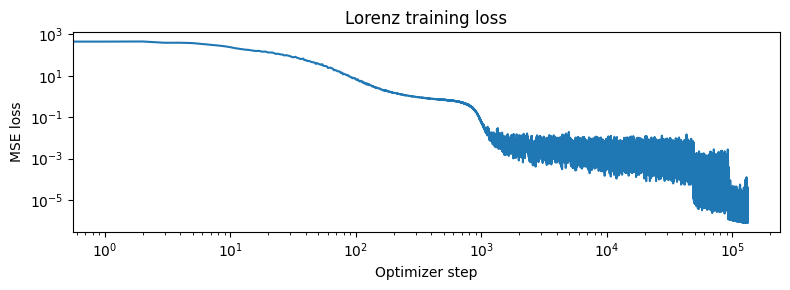

In [7]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.loglog(loss_history)
ax.set_xlabel("Optimizer step")
ax.set_ylabel("MSE loss")
ax.set_title("Lorenz training loss")
plt.tight_layout()
plt.show()

## Evaluation: Attractor Comparison

Run a long autoregressive rollout from a single initial condition and compare the
model-generated attractor against the ground-truth trajectory.
The rollout is cached to disk so re-running the cell is fast.

`NUM_ROLLOUTS` controls the length: each rollout covers `N * (N_t - 1)` time steps,
so 5 000 rollouts ≈ 550 000 time steps at Δt = 0.1 — enough to trace the full attractor.

In [ ]:
import os
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from scipy.signal import find_peaks

nn_rhs_model.eval()

NUM_ROLLOUTS = 50_000  # increase for a denser attractor and better statistics
ROLLOUT_CACHE = "lorenz_attractor_rollout.pt"

# Use the first trajectory in the dataset as the initial condition
test_loader = StaggeredODEDataLoader(dataset, batch_size=1, shuffle=False)
test_batch = next(iter(test_loader))

if os.path.exists(ROLLOUT_CACHE):
    print(f"Loading cached rollout from {ROLLOUT_CACHE}")
    _cache = torch.load(ROLLOUT_CACHE, map_location=device)
    u_hat_rollout = _cache["u_hat_rollout"]
else:
    print(f"Running {NUM_ROLLOUTS}-rollout inference...")
    with torch.no_grad():
        _, u_hat_rollout = solver.rollout_batch(test_batch, num_rollouts=NUM_ROLLOUTS)
    torch.save({"u_hat_rollout": u_hat_rollout}, ROLLOUT_CACHE)
    print(f"Saved to {ROLLOUT_CACHE}")

print(f"Rollout shape: {u_hat_rollout.shape}  (batch, time, fields)")

Running 50000-rollout inference...
rebuilding indexers... 
done rebuilding indexers


/home/kinch/miniconda3/envs/whitney/lib/python3.12/site-packages/torch/autograd/graph.py:829: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:179.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


In [ ]:
# Rescale from normalised space back to physical Lorenz coordinates
u_std = dataset.u_hats_std.squeeze(0).cpu()  # (3,)
u_mean = dataset.u_hats_mean.squeeze(0).cpu()  # (3,)

u_model = u_hat_rollout[0].cpu() * u_std + u_mean  # (T, 3)  model
u_data = (dataset.u_hats.cpu().reshape(-1, num_fields) * u_std + u_mean)[
    : 2 * u_hat_rollout.shape[1] : 2
]  # (T, 3)  ground truth

data_np = u_data.numpy()
model_np = u_model.numpy()
print(f"Trajectory length: {len(data_np)} steps")

Trajectory length: 50000 steps


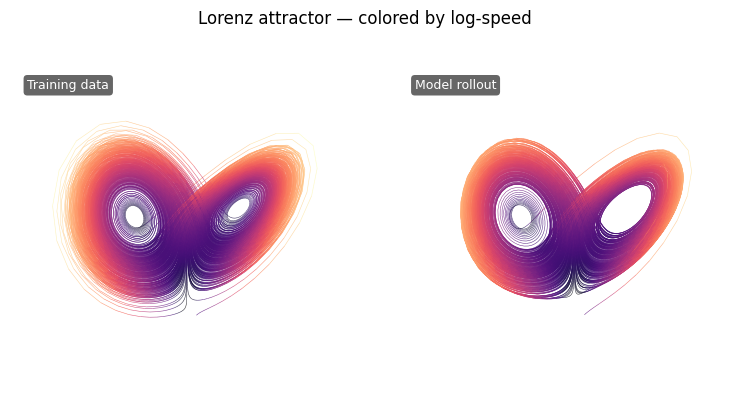

In [ ]:
# ── 3-D attractor comparison, coloured by log-speed ─────────────────────────
_stride = 2  # thin the trajectory for faster rendering
_d = data_np[::_stride]
_m = model_np[::_stride]
_all = np.vstack([_d, _m])
_lims = [(_all[:, i].min(), _all[:, i].max()) for i in range(3)]


def _segments(arr):
    pts = arr.reshape(-1, 1, 3)
    return np.concatenate([pts[:-1], pts[1:]], axis=1)


def _log_speed(arr):
    return np.log1p(np.linalg.norm(np.diff(arr, axis=0), axis=1))


_all_ls = np.concatenate([_log_speed(_d), _log_speed(_m)])
_ls_min, _ls_max = _all_ls.min(), _all_ls.max()

_label_kw = dict(
    fontsize=9,
    color="white",
    bbox=dict(facecolor="black", alpha=0.6, edgecolor="none", boxstyle="round,pad=0.3"),
)

fig = plt.figure(figsize=(10, 4.5))
for col, (arr, title) in enumerate([(_d, "Training data"), (_m, "Model rollout")]):
    ax = fig.add_subplot(1, 2, col + 1, projection="3d")
    lc = Line3DCollection(_segments(arr), cmap="magma", alpha=0.85)
    lc.set_array(_log_speed(arr))
    lc.set_clim(_ls_min, _ls_max)
    lc.set_linewidth(0.4)
    ax.add_collection3d(lc)
    for i, (lo, hi) in enumerate(_lims):
        [ax.set_xlim, ax.set_ylim, ax.set_zlim][i](lo, hi)
    ax.set_box_aspect([_lims[i][1] - _lims[i][0] for i in range(3)])
    ax.set_axis_off()
    ax.view_init(elev=25, azim=-55)
    ax.text2D(0.05, 0.93, title, transform=ax.transAxes, va="top", **_label_kw)

plt.subplots_adjust(wspace=0.0)
plt.suptitle("Lorenz attractor — colored by log-speed")
plt.show()

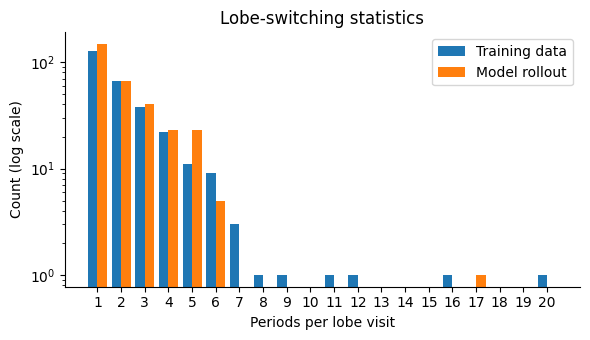

In [ ]:
# ── Lobe-switching statistics ─────────────────────────────────────────────────
# Count z-oscillation peaks per lobe visit (left / right wing of the attractor).
# A well-trained model should reproduce this distribution.


def _lobe_period_counts(traj):
    """For each contiguous lobe segment (x > 0 or x < 0), count z-peaks."""
    x, z = traj[:, 0], traj[:, 2]
    switches = np.where(np.diff(np.sign(x)) != 0)[0] + 1
    seg_starts = np.concatenate(([0], switches))
    seg_ends = np.concatenate((switches, [len(x)]))
    prominence = np.std(z) * 0.3
    counts = []
    for s, e in zip(seg_starts, seg_ends):
        if e - s < 10:
            continue
        peaks, _ = find_peaks(z[s:e], prominence=prominence, distance=5)
        if len(peaks):
            counts.append(len(peaks))
    return np.array(counts)


counts_data = _lobe_period_counts(data_np)
counts_model = _lobe_period_counts(model_np)

_max = max(counts_data.max(), counts_model.max())
bins = np.arange(1, _max + 2) - 0.5
x_centers = bins[:-1] + 0.5
hist_data, _ = np.histogram(counts_data, bins=bins)
hist_model, _ = np.histogram(counts_model, bins=bins)

fig, ax = plt.subplots(figsize=(6, 3.5))
w = 0.4
ax.bar(x_centers - w / 2, hist_data, width=w, label="Training data")
ax.bar(x_centers + w / 2, hist_model, width=w, label="Model rollout")
ax.set_yscale("log")
ax.set_xticks(np.arange(1, _max + 1))
ax.set_xlabel("Periods per lobe visit")
ax.set_ylabel("Count (log scale)")
ax.set_title("Lobe-switching statistics")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()